# Gabarito — Polígonos Regulares e Comprimento da Circunferência

Este notebook traz a resolução comentada dos exercícios de [`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb).

⚠️ **Antes de olhar aqui:** tente resolver os exercícios sozinho no notebook original e use as células de verificação (`assert`) para conferir sua resposta. Volte a este gabarito só depois de tentar — ou se travar de verdade em algum passo.

In [1]:
# Imports e ferramentas necessários para os exercícios abaixo (reconstruídos do notebook principal)
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Arc, Circle, Polygon, Wedge

# Paleta de cores Nord
NORD_FUNDO = "#2E3440"
NORD_PAINEL = "#3B4252"
NORD_LINHA = "#4C566A"
NORD_TEXTO = "#ECEFF4"
NORD_TEXTO_SEC = "#D8DEE9"
COR_PONTO = "#88C0D0"
COR_DESTAQUE = "#A3BE8C"
COR_ALERTA = "#BF616A"
COR_SECUNDARIA = "#81A1C1"
COR_EXTRA = "#B48EAD"
COR_AVISO = "#EBCB8B"


def estilizar_eixo(ax) -> None:
    """Aplica o estilo Nord padrão a um eixo do matplotlib."""
    ax.set_facecolor(NORD_FUNDO)
    ax.tick_params(colors=NORD_TEXTO_SEC)
    for spine in ax.spines.values():
        spine.set_color(NORD_LINHA)
    ax.grid(color=NORD_LINHA, linewidth=0.5, alpha=0.5)


# Ferramentas do notebook principal e dos anteriores (0401a, 0402a, 0407a, 0410a, 0411a, 0412a e 0415a)

def preparar_eixo(ax, pontos, margem: float = 0.8) -> None:
    """Deixa o eixo pronto para desenhos de geometria (estilo Nord, sem grade, sem números,
    escala igual) e enquadra todos os `pontos` com uma margem em volta."""
    estilizar_eixo(ax)
    ax.grid(False)
    xs = [p[0] for p in pontos]
    ys = [p[1] for p in pontos]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def direcao(angulo_graus: float) -> np.ndarray:
    """Vetor de tamanho 1 apontando na direção dada, em graus, a partir da horizontal (sentido anti-horário).

    (cos e sin vêm da Trigonometria, módulo 05; aqui só servem para apontar na direção certa.)
    """
    rad = math.radians(angulo_graus)
    return np.array([math.cos(rad), math.sin(rad)])


def direcao_de(origem, destino) -> float:
    """Direção, em graus, em que `destino` está quando visto de `origem`."""
    return math.degrees(math.atan2(destino[1] - origem[1], destino[0] - origem[0]))


def medir_angulo(vertice, P, Q) -> float:
    """Transferidor digital: medida, em graus, do ângulo com vértice em `vertice`
    formado pelas semirretas que passam por P e por Q (resultado entre 0° e 180°)."""
    u = np.subtract(P, vertice)
    v = np.subtract(Q, vertice)
    cosseno = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
    return math.degrees(math.acos(np.clip(cosseno, -1, 1)))


def cruzamento(P, inclinacao_1: float, Q, inclinacao_2: float):
    """Ponto em que a reta que passa por P (com a inclinação `inclinacao_1`, em graus) cruza a reta
    que passa por Q (com a inclinação `inclinacao_2`). Devolve None se as duas retas tiverem a mesma
    direção, porque aí elas não se cruzam num ponto só.

    Por trás, é um sistema linear 2×2 (módulo 03): P + t·u = Q + k·v, com incógnitas t e k.
    """
    matriz = np.column_stack([direcao(inclinacao_1), -direcao(inclinacao_2)])
    if abs(np.linalg.det(matriz)) < 1e-12:
        return None
    t, _ = np.linalg.solve(matriz, np.subtract(Q, P))
    return np.array(P, dtype=float) + t * direcao(inclinacao_1)


def ponto_medio(P, Q) -> np.ndarray:
    """Ponto médio do segmento PQ: a média das coordenadas (0402a)."""
    return (np.asarray(P, dtype=float) + np.asarray(Q, dtype=float)) / 2


def iguais(x: float, y: float) -> bool:
    """Compara duas medidas com uma tolerância pequena (as contas com float têm arredondamentos)."""
    return math.isclose(x, y, rel_tol=1e-9, abs_tol=1e-6)


def desenhar_ponto(ax, p, nome: str = "", cor: str = COR_AVISO, deslocamento=(0.12, 0.15),
                   tamanho_fonte: int = 13) -> None:
    """Desenha um ponto com seu nome (letra maiúscula) ao lado."""
    ax.plot(*p, "o", color=cor, markersize=7, zorder=6)
    if nome:
        ax.text(p[0] + deslocamento[0], p[1] + deslocamento[1], nome, color=NORD_TEXTO, fontsize=tamanho_fonte,
                fontweight="bold", zorder=7)


def desenhar_segmento(ax, P, Q, cor: str = NORD_TEXTO, largura: float = 3.0, estilo: str = "-",
                      alpha: float = 1.0, zorder: int = 5) -> None:
    """Desenha o segmento PQ (só o pedaço entre P e Q)."""
    ax.plot(*zip(P, Q), color=cor, lw=largura, linestyle=estilo, alpha=alpha, zorder=zorder,
            solid_capstyle="round")


def desenhar_setor(ax, vertice, inicio: float, abertura: float, raio: float = 0.5, cor: str = COR_PONTO,
                   rotulo: str | None = None, marcar_reto: bool = True, raio_rotulo: float | None = None,
                   tamanho_fonte: int = 11) -> None:
    """Pinta o ângulo com vértice em `vertice` que começa na direção `inicio` e gira `abertura`
    graus no sentido anti-horário. O ângulo reto ganha o quadradinho no lugar do arco."""
    v = np.array(vertice, dtype=float)
    if marcar_reto and math.isclose(abertura, 90, abs_tol=1e-6):
        lado = 0.6 * raio
        canto = [v, v + lado * direcao(inicio), v + lado * (direcao(inicio) + direcao(inicio + 90)),
                 v + lado * direcao(inicio + 90)]
        ax.add_patch(Polygon(canto, closed=True, facecolor=cor, alpha=0.35, edgecolor=cor, lw=2))
    else:
        ax.add_patch(Wedge(v, raio, inicio, inicio + abertura, facecolor=cor, alpha=0.3, edgecolor="none"))
        ax.add_patch(Arc(v, 2 * raio, 2 * raio, theta1=inicio, theta2=inicio + abertura, color=cor, lw=2))
    if rotulo:
        distancia_rotulo = 1.6 * raio if raio_rotulo is None else raio_rotulo
        posicao = v + distancia_rotulo * direcao(inicio + abertura / 2)
        ax.text(*posicao, rotulo, color=cor, fontsize=tamanho_fonte, ha="center", va="center", fontweight="bold")


def desenhar_arco(ax, vertice, p, q, **opcoes) -> None:
    """Marca o ângulo de vértice `vertice` formado pelas semirretas que passam por p e por q
    (sempre a abertura menor, entre 0° e 180°). Aceita as mesmas opções de `desenhar_setor`."""
    inicio = direcao_de(vertice, p) % 360
    abertura = (direcao_de(vertice, q) - inicio) % 360
    if abertura > 180:
        inicio, abertura = direcao_de(vertice, q) % 360, 360 - abertura
    desenhar_setor(ax, vertice, inicio, abertura, **opcoes)


def rotular_fora(ax, P, texto: str, centro, cor: str = NORD_TEXTO, distancia: float = 0.35,
                 tamanho: int = 12) -> None:
    """Escreve `texto` perto do ponto P, afastado do `centro` (para não ficar em cima da figura)."""
    P = np.asarray(P, dtype=float)
    afastar = P - np.asarray(centro, dtype=float)
    afastar = afastar / np.linalg.norm(afastar) if np.linalg.norm(afastar) > 0 else np.array([0.0, 1.0])
    ax.text(*(P + distancia * afastar), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def rotular_segmento(ax, P, Q, texto: str, cor: str = NORD_TEXTO, distancia: float = 0.35, longe_de=None,
                     tamanho: int = 11) -> None:
    """Escreve `texto` ao lado do meio do segmento PQ, afastado `distancia` na direção perpendicular a ele.
    Se `longe_de` for um ponto, o texto vai para o lado do segmento oposto a esse ponto."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    if longe_de is not None and np.dot(meio - np.asarray(longe_de, dtype=float), normal) < 0:
        normal = -normal
    ax.text(*(meio + distancia * normal), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def escrever_checklist(ax, itens, titulo: str = "") -> None:
    """Painel de texto com uma linha por item (texto, ok): ✓ verde quando vale, ✗ vermelho quando não (0410a)."""
    ax.set_facecolor(NORD_FUNDO)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    if titulo:
        ax.text(0.0, 0.97, titulo, color=NORD_TEXTO, fontsize=12, fontweight="bold", va="top")
    passo = min(0.13, 0.85 / max(len(itens), 1))
    for k, (texto, ok) in enumerate(itens):
        ax.text(0.0, 0.84 - k * passo, f"{'✓' if ok else '✗'}  {texto}", color=COR_DESTAQUE if ok else COR_ALERTA,
                fontsize=11, va="top")


def desenhar_circunferencia(ax, O, r: float, cor: str = COR_PONTO, estilo: str = "-",
                            largura: float = 2.5, preencher: bool = False, opacidade: float = 0.15) -> None:
    """Desenha a circunferência de centro O e raio r (a linha). Com `preencher=True`, pinta também a
    região interna: o círculo (0412a)."""
    O = tuple(np.asarray(O, dtype=float))
    if preencher:
        ax.add_patch(Circle(O, r, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=1))
    ax.add_patch(Circle(O, r, fill=False, edgecolor=cor, lw=largura, linestyle=estilo, zorder=3))


def cruzamento_circunferencias(P, r1: float, Q, r2: float):
    """Um ponto comum às circunferências λ(P, r1) e λ(Q, r2): o que fica à ESQUERDA de quem anda de P para Q
    (0415a). Devolve None se as duas circunferências não se cruzam."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    d = math.dist(P, Q)
    if not abs(r1 - r2) < d < r1 + r2:
        return None
    x = (d**2 + r1**2 - r2**2) / (2 * d)
    y = math.sqrt(r1**2 - x**2)
    u = (Q - P) / d
    return P + x * u + y * np.array([-u[1], u[0]])



# Ferramentas do notebook principal
# Notação fixa: n = número de lados; ℓ = lado (verde); R = raio da circunscrita (azul); a = apótema = raio da
# inscrita (laranja); α = ângulo central (amarelo). O polígono inscrito é azul-claro e o circunscrito é roxo.
COR_POLIGONO = COR_PONTO  # polígono regular (inscrito): azul-claro
COR_LADO = COR_DESTAQUE  # lado ℓ: verde
COR_RAIO = COR_SECUNDARIA  # raio R e circunferência circunscrita: azul (tom frio)
COR_CIRCUNSCRITA = COR_SECUNDARIA
COR_APOTEMA = "#D08770"  # apótema a e circunferência inscrita: laranja (tom quente)
COR_INSCRITA = "#D08770"
COR_CENTRAL = COR_AVISO  # ângulo central α e arcos medidos: amarelo
COR_INTERNO = "#8FBCBB"  # ângulo interno: verde-água
COR_EXTERNO = COR_EXTRA  # ângulo externo: roxo
COR_CIRCUNSCRITO = COR_EXTRA  # polígono circunscrito: roxo


def vertices_regular(n: int, R: float = 1.0, centro=(0.0, 0.0), rotacao: float | None = None) -> np.ndarray:
    """Vértices do polígono regular de n lados inscrito na circunferência λ(centro, R): n pontos dela separados
    por 360°/n, o primeiro na direção `rotacao` (em graus). Sem `rotacao`, o polígono fica "apoiado" num lado
    horizontal: o lado entre os vértices 0 e 1 é o de baixo (0411a).

    (A direção de cada vértice usa `direcao`, que vem da Trigonometria; aqui ela só aponta os vértices.)
    """
    inicio = -90 - 180 / n if rotacao is None else rotacao
    c = np.asarray(centro, dtype=float)
    return np.array([c + R * direcao(inicio + 360 * k / n) for k in range(n)])

def desenhar_poligono(ax, vertices, cor: str = COR_POLIGONO, largura: float = 2.5, preencher: bool = True,
                      opacidade: float = 0.15, estilo: str = "-", zorder: int = 4) -> None:
    """Desenha o polígono de vértices dados (fechado), com preenchimento claro opcional."""
    if preencher:
        ax.add_patch(Polygon(vertices, closed=True, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=1))
    ax.add_patch(Polygon(vertices, closed=True, fill=False, edgecolor=cor, lw=largura, linestyle=estilo,
                         zorder=zorder))

def angulo_central(n: int) -> float:
    """Ângulo central do polígono regular de n lados: α = 360°/n."""
    return 360 / n

def angulo_externo(n: int) -> float:
    """Ângulo externo do polígono regular de n lados: a_e = 360°/n (os n externos somam 360°)."""
    return 360 / n

def angulo_interno(n: int) -> float:
    """Ângulo interno do polígono regular de n lados: a_i = 180° − a_e = (n − 2)·180°/n."""
    return (n - 2) * 180 / n

def lado_de_R(n: int, R: float) -> float:
    """Lado ℓ MEDIDO nas coordenadas: a distância entre dois vértices consecutivos."""
    V = vertices_regular(n, R)
    return math.dist(V[0], V[1])

def apotema_de_R(n: int, R: float) -> float:
    """Apótema a MEDIDO nas coordenadas: a distância do centro ao ponto médio de um lado."""
    V = vertices_regular(n, R)
    return math.dist((0, 0), ponto_medio(V[0], V[1]))

def dobrar_lado(lado: float, R: float = 1.0) -> float:
    """Lado ℓ₂ₙ do polígono regular de 2n lados inscrito em λ(O, R), a partir do lado ℓₙ (Pitágoras duas vezes):
    ℓ₂ₙ = √(2R² − R·√(4R² − ℓₙ²))."""
    return math.sqrt(2 * R**2 - R * math.sqrt(4 * R**2 - lado**2))

def lado_inscrito(n: int, R: float = 1.0) -> float:
    """Lado do polígono regular de n lados inscrito em λ(O, R), só com Pitágoras e os triângulos notáveis:
    fórmulas fechadas para n = 3, 4 e 6 e, para os demais, dobras a partir delas."""
    fechadas = {3: R * math.sqrt(3), 4: R * math.sqrt(2), 6: R}
    if n in fechadas:
        return fechadas[n]
    if n % 2 == 0 and n > 6:
        return dobrar_lado(lado_inscrito(n // 2, R), R)
    raise ValueError(f"o lado do polígono de {n} lados não sai por dobras de 3, 4 ou 6 (use lado_de_R)")

def apotema_inscrito(n: int, R: float = 1.0) -> float:
    """Apótema do polígono regular de n lados inscrito em λ(O, R), por Pitágoras: a = √(R² − ℓ²/4)."""
    return math.sqrt(R**2 - lado_inscrito(n, R) ** 2 / 4)

def perimetro_regular(n: int, R: float = 1.0) -> float:
    """Perímetro 2p = n·ℓ do polígono regular de n lados inscrito em λ(O, R)."""
    return n * lado_de_R(n, R)

def area_regular(n: int, R: float = 1.0) -> float:
    """Área do polígono regular de n lados inscrito em λ(O, R): S = p·a (semiperímetro × apótema)."""
    return perimetro_regular(n, R) / 2 * apotema_de_R(n, R)

def area_por_coordenadas(vertices) -> float:
    """Área de um polígono convexo de vértices dados, somando os triângulos O V_k V_(k+1) com o centro O = média
    dos vértices: cada triângulo tem área |det[V_k − O, V_(k+1) − O]|/2 (0305a)."""
    V = np.asarray(vertices, dtype=float)
    O = V.mean(axis=0)
    return sum(abs(np.linalg.det(np.array([V[k] - O, V[(k + 1) % len(V)] - O]))) / 2 for k in range(len(V)))

def poligono_circunscrito(n: int, r: float = 1.0) -> np.ndarray:
    """Vértices do polígono regular de n lados CIRCUNSCRITO a λ(O, r): o inscrito ampliado, com centro em O,
    na razão r/aₙ (cada vértice desliza para fora ao longo do próprio raio)."""
    return vertices_regular(n, r) * (r / apotema_de_R(n, r))

def comprimento_circunferencia(r: float) -> float:
    """Comprimento da circunferência de raio r: C = 2πr."""
    return 2 * math.pi * r

def comprimento_arco(r: float, alfa_graus: float) -> float:
    """Comprimento do arco de α graus numa circunferência de raio r: (α/360°)·2πr."""
    return alfa_graus / 360 * comprimento_circunferencia(r)

def cotas_arquimedes(passos: int) -> list[tuple[int, float, float]]:
    """Cotas (n, p_n, P_n) para π, com p_n e P_n os semiperímetros do inscrito e do circunscrito em λ(O, 1), do
    hexágono até n = 6·2^passos, pelas médias: P₂ₙ = 2pP/(p + P) e p₂ₙ = √(p·P₂ₙ)."""
    n, p, P = 6, 3.0, 2 * math.sqrt(3)
    historico = [(n, p, P)]
    for _ in range(passos):
        P = 2 * p * P / (p + P)
        p = math.sqrt(p * P)
        n *= 2
        historico.append((n, p, P))
    return historico

## Básico

**Exercício 1.** Ângulos dos polígonos regulares.

In [2]:
# (a) Decágono: central = externo = 360°/10 = 36°; interno = 8·180°/10 = 144° (ou 180° − 36°)
angulos_ex1a = (360 / 10, (10 - 2) * 180 / 10, 360 / 10)

# (b) Externo de 24°: n = 360°/24° = 15
n_ex1b = round(360 / 24)

# (c) Interno de 165° ⇒ externo de 180° − 165° = 15° ⇒ n = 360°/15° = 24
n_ex1c = round(360 / (180 - 165))

# (d) Interno do polígono de 15 lados: 180° − 24° = 156° (confere com 13·180°/15)
interno_ex1d = 180 - 24

print(angulos_ex1a, n_ex1b, n_ex1c, interno_ex1d)
print("conferência:", angulo_interno(15), angulo_interno(24))

(36.0, 144.0, 36.0) 15 24 156
conferência: 156.0 165.0


O caminho mais curto para achar $n$ é sempre pelo **externo**, porque $a_e = \frac{360°}{n}$ é uma fórmula com $n$ num lugar só. Pelo interno, seria preciso resolver $\frac{(n - 2) \cdot 180}{n} = 165$, isto é, $180n - 360 = 165n$, que dá o mesmo $n = 24$ com mais trabalho. O `round` só transforma o resultado da divisão (um `float`) num inteiro.

**Exercício 2.** Os regulares de bolso.

In [3]:
# (a) Hexágono de lado 6: R = ℓ = 6; a = R√3/2 = 3√3; S = p·a = 18·3√3 = 54√3
apotema_ex2a = 6 * math.sqrt(3) / 2
area_ex2a = (6 * 6 / 2) * apotema_ex2a

# (b) Quadrado inscrito em R = 5: ℓ = R√2 = 5√2; a = ℓ/2; S = ℓ² = 50 (ou 2R²)
lado_ex2b = 5 * math.sqrt(2)
apotema_ex2b = lado_ex2b / 2
area_ex2b = lado_ex2b**2

# (c) Triângulo equilátero inscrito em R = 4: ℓ = R√3 = 4√3; a = R/2 = 2; p = 3ℓ/2 = 6√3; S = p·a = 12√3
lado_ex2c = 4 * math.sqrt(3)
apotema_ex2c = 4 / 2
area_ex2c = (3 * lado_ex2c / 2) * apotema_ex2c

# (d) Triângulo equilátero de lado 9: R = ℓ/√3 = 3√3; a = R/2
R_ex2d = 9 / math.sqrt(3)
apotema_ex2d = R_ex2d / 2

print(apotema_ex2a, area_ex2a, lado_ex2b, apotema_ex2b, area_ex2b, lado_ex2c, apotema_ex2c, area_ex2c, R_ex2d, apotema_ex2d)
# Conferências com as funções do notebook (lado_inscrito, apotema_inscrito e area_regular)
print(apotema_inscrito(6, 6), area_regular(6, 6), area_regular(4, 5), area_regular(3, 4), lado_inscrito(3, R_ex2d))

5.196152422706632 93.53074360871938 7.0710678118654755 3.5355339059327378 50.00000000000001 6.928203230275509 2.0 20.784609690826528 5.196152422706632 2.598076211353316
5.196152422706632 93.53074360871938 50.00000000000001 20.784609690826525 9.0


Em (c), a área também sai da fórmula do equilátero de 0416a, $\frac{\ell^2\sqrt{3}}{4} = \frac{48\sqrt{3}}{4} = 12\sqrt{3}$: as duas fórmulas têm que concordar. Em (d), $R = 3\sqrt{3} \approx 5{,}20$ e $a = \frac{3\sqrt{3}}{2} \approx 2{,}60$: o circuncentro divide a altura $\frac{9\sqrt{3}}{2}$ na razão $2 : 1$, como em 0410a.

**Exercício 3.** Comprimento da circunferência e de arcos.

In [4]:
# (a) C = 2πr = 16π
C_ex3a = 2 * math.pi * 8

# (b) 90° é 1/4 da volta: (90/360)·16π = 4π
arco_ex3b = 90 / 360 * C_ex3a

# (c) Em metros: cada volta anda π·0,6 m; em 100 m, 100/(0,6π) ≈ 53,05 voltas
voltas_ex3c = 100 / (math.pi * 0.6)

# (d) Em 20 min, o ponteiro de minutos dá 20/60 de volta = 120°: (120/360)·2π·10 = 20π/3
ponta_ex3d = 120 / 360 * 2 * math.pi * 10

# (e) (45/360)·2πr = 3π  ⇒  (πr)/4 = 3π  ⇒  r = 12
raio_ex3e = 3 * math.pi / (45 / 360 * 2 * math.pi)

print(C_ex3a, arco_ex3b, voltas_ex3c, ponta_ex3d, raio_ex3e)

50.26548245743669 12.566370614359172 53.05164769729845 20.94395102393195 12.0


Em (c), a armadilha é misturar unidades: com o diâmetro em centímetros (60) e a distância em metros (100), a conta daria $\approx 0{,}53$ volta. Em (e), $\pi$ se cancela: com arcos "em múltiplos de $\pi$", as contas costumam ficar exatas.

## Intermediário

**Exercício 4.** As suas próprias funções, conferidas com coordenadas.

In [5]:
def vertices_regular_ex4(n: int, R: float) -> np.ndarray:
    # n pontos de λ(O, R), um a cada 360°/n, começando na direção 0°
    return np.array([R * direcao(360 * k / n) for k in range(n)])


def lado_ex4(n: int, R: float) -> float:
    V = vertices_regular_ex4(n, R)
    return math.dist(V[0], V[1])


def apotema_ex4(n: int, R: float) -> float:
    # Triângulo OMB, retângulo em M: R² = a² + (ℓ/2)²
    return math.sqrt(R**2 - (lado_ex4(n, R) / 2) ** 2)


def area_regular_ex4(n: int, R: float) -> float:
    p = n * lado_ex4(n, R) / 2  # SEMIperímetro
    return p * apotema_ex4(n, R)


def dobrar_lado_ex4(lado: float, R: float) -> float:
    # Pitágoras duas vezes: ℓ₂ₙ² = (ℓₙ/2)² + (R − aₙ)² = 2R² − 2R·aₙ, com 2aₙ = √(4R² − ℓₙ²)
    return math.sqrt(2 * R**2 - R * math.sqrt(4 * R**2 - lado**2))


def comprimento_arco_ex4(r: float, alfa_graus: float) -> float:
    return alfa_graus / 360 * 2 * math.pi * r


print(lado_ex4(6, 1), apotema_ex4(6, 1), area_regular_ex4(6, 1), dobrar_lado_ex4(1, 1), comprimento_arco_ex4(1, 180))

# A mesma conferência da célula de verificação: tudo contra medições diretas
erros = []
for n in range(3, 21):
    for R in (1.0, 3.5):
        erros.append(abs(area_regular_ex4(n, R) - area_por_coordenadas(vertices_regular(n, R))))
        erros.append(abs(dobrar_lado_ex4(lado_de_R(n, R), R) - lado_de_R(2 * n, R)))
print(f"maior diferença entre as funções e as medições diretas: {max(erros):.2e}")

0.9999999999999999 0.8660254037844386 2.5980762113533156 0.5176380902050416 3.141592653589793
maior diferença entre as funções e as medições diretas: 7.11e-15


A rotação dos vértices não importa: começando em $0°$ (como aqui) ou com um lado "deitado" (como em `vertices_regular`), o polígono é o mesmo, só girado, e todas as medidas coincidem. Repare na ordem das funções: `apotema_ex4` reaproveita `lado_ex4`, e `area_regular_ex4` reaproveita as duas. O erro mais comum é usar o perímetro inteiro na área (`n * lado * apotema`), que dá o dobro.

**Exercício 5.** O sanduíche em código.

In [6]:
def perimetro_circunscrito(n: int) -> float:
    # Circunscrito = inscrito ampliado na razão r/aₙ (com r = 1)
    return perimetro_regular(n) / apotema_de_R(n, 1)


# (a) As duas desigualdades para cada n
sanduiche_ok_ex5 = all(perimetro_regular(n) < 2 * math.pi < perimetro_circunscrito(n) for n in range(3, 201))

# (b) O primeiro n em que as duas folgas ficam abaixo de 0,01
n_min_ex5 = next(n for n in range(3, 10_000)
                 if 2 * math.pi - perimetro_regular(n) < 0.01 and perimetro_circunscrito(n) - 2 * math.pi < 0.01)

print(sanduiche_ok_ex5, n_min_ex5)
for n in (10, 20, 33, 45, 46):
    print(f"n = {n:>2}: folga de baixo = {2 * math.pi - perimetro_regular(n):.5f}   "
          f"folga de cima = {perimetro_circunscrito(n) - 2 * math.pi:.5f}")

True 46
n = 10: folga de baixo = 0.10285   folga de cima = 0.21521
n = 20: folga de baixo = 0.02581   folga de cima = 0.05219
n = 33: folga de baixo = 0.00949   folga de cima = 0.01905
n = 45: folga de baixo = 0.00510   folga de cima = 0.01023
n = 46: folga de baixo = 0.00488   folga de cima = 0.00979


A folga de cima (circunscrito) é sempre cerca do **dobro** da folga de baixo (inscrito): com $n = 33$ a de baixo já é menor que 0,01, mas a de cima só chega lá em $n = 46$. É por isso que, na seção 4, a **média** dos dois perímetros ficava tão perto de $2\pi$; uma média ponderada esperta, $\frac{2 \cdot \text{inscrito} + \text{circunscrito}}{3}$, chega mais perto ainda (experimente!).

**Exercício 6.** Problemas de dois ou três passos.

5.999999999999999 5.999999999999999 5.196152422706631 1.9999999999999996 2.928932188134525 4.142135623730951
(b) por coordenadas: 2.0000000000000004
lados: [4.142136 4.142136 4.142136 4.142136 4.142136 4.142136 4.142136 4.142136]  distâncias ao centro: [5.411961 5.411961 5.411961 5.411961 5.411961 5.411961 5.411961 5.411961]


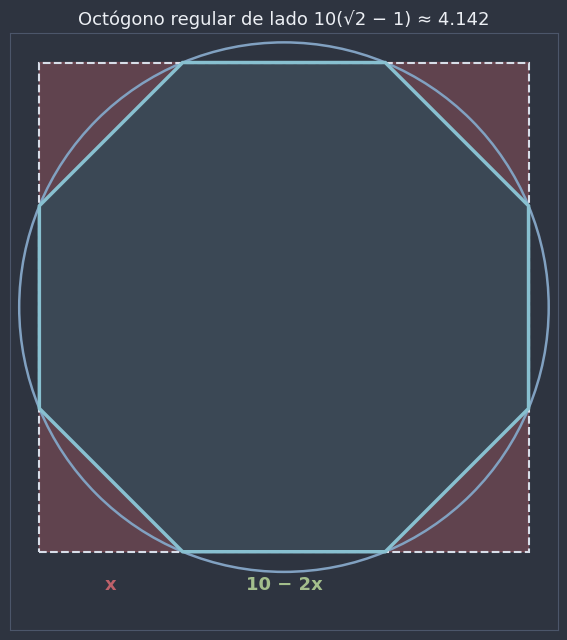

In [7]:
# (a) (3√3/2)·ℓ² = 54√3  ⇒  ℓ² = 36  ⇒  ℓ = 6; no hexágono, R = ℓ e a = ℓ√3/2
lado_ex6a = math.sqrt(54 * math.sqrt(3) / (3 * math.sqrt(3) / 2))
R_ex6a = lado_ex6a
apotema_ex6a = lado_ex6a * math.sqrt(3) / 2

# (b) Circunscrito e inscrito com o mesmo n são semelhantes na razão k = r/a₄ = 1/(√2/2) = √2; áreas: k² = 2
razao_ex6b = (1 / (math.sqrt(2) / 2)) ** 2

# (c) x√2 = 10 − 2x  ⇒  x(2 + √2) = 10  ⇒  x = 10/(2 + √2) = 5(2 − √2) ≈ 2,929; lado = x√2 = 10(√2 − 1)
corte_ex6c = 10 / (2 + math.sqrt(2))
lado_octogono_ex6c = corte_ex6c * math.sqrt(2)

print(lado_ex6a, R_ex6a, apotema_ex6a, razao_ex6b, corte_ex6c, lado_octogono_ex6c)
print("(b) por coordenadas:", area_por_coordenadas(poligono_circunscrito(4, 1)) / area_regular(4, 1))

# (c) Conferência: os 8 vértices do octógono cortado estão todos à mesma distância do centro do quadrado?
x = corte_ex6c
octogono = np.array([(x, 0), (10 - x, 0), (10, x), (10, 10 - x), (10 - x, 10), (x, 10), (0, 10 - x), (0, x)])
lados_oct = [math.dist(octogono[k], octogono[(k + 1) % 8]) for k in range(8)]
raios_oct = [math.dist((5, 5), P) for P in octogono]
print("lados:", np.round(lados_oct, 6), " distâncias ao centro:", np.round(raios_oct, 6))

fig, ax = plt.subplots(figsize=(6.5, 6.5))
fig.patch.set_facecolor(NORD_FUNDO)
desenhar_poligono(ax, [(0, 0), (10, 0), (10, 10), (0, 10)], cor=NORD_TEXTO_SEC, preencher=False, largura=1.5, estilo="--")
for canto in ([(0, 0), (x, 0), (0, x)], [(10, 0), (10, x), (10 - x, 0)], [(10, 10), (10 - x, 10), (10, 10 - x)],
              [(0, 10), (0, 10 - x), (x, 10)]):
    ax.add_patch(Polygon(canto, closed=True, facecolor=COR_ALERTA, alpha=0.35, edgecolor=COR_ALERTA))
desenhar_poligono(ax, octogono, cor=COR_POLIGONO)
desenhar_circunferencia(ax, (5, 5), raios_oct[0], cor=COR_CIRCUNSCRITA, largura=1.8)
ax.text(x / 2, -0.5, "x", color=COR_ALERTA, fontsize=13, fontweight="bold", ha="center", va="top")
ax.text(5, -0.5, "10 − 2x", color=COR_LADO, fontsize=13, fontweight="bold", ha="center", va="top")
preparar_eixo(ax, [(0, -1), (10, 10)], margem=0.6)
ax.set_title(f"Octógono regular de lado 10(√2 − 1) ≈ {lado_octogono_ex6c:.3f}", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

Em (b), a razão 2 também sai sem semelhança: o quadrado inscrito tem diagonal $2r$ (área $\frac{(2r)^2}{2} = 2r^2$) e o circunscrito tem lado $2r$ (área $4r^2$). Em (c), cortar os cantos com $x = 5(2 - \sqrt{2}) \approx 2{,}93$ deixa os oito lados iguais e os oito ângulos de $135°$ (cada canto cortado é um 45°–45°–90°): o octógono é regular, e a conferência mostra os oito vértices sobre uma mesma circunferência.

**Exercício 7.** Pistas e odômetros.

In [8]:
# (a) Duas retas de 100 m + duas semicircunferências de raio 30 (= uma circunferência inteira)
pista_ex7a = 2 * 100 + 2 * math.pi * 30

# (b) A raia de fora: as retas são iguais; as curvas somam 2π·31,2
diferenca_ex7b = (2 * 100 + 2 * math.pi * 31.2) - pista_ex7a

# (c) Com curvas de raio 50: 2π·51,2 − 2π·50 = 2π·1,2 de novo
diferenca_ex7c = (2 * 100 + 2 * math.pi * 51.2) - (2 * 100 + 2 * math.pi * 50)

# (d) 1000 voltas de π·0,66 m = 2073,5 m = 2,0735 km
distancia_ex7d = 1000 * math.pi * 0.66 / 1000

print(pista_ex7a, diferenca_ex7b, diferenca_ex7c, distancia_ex7d)

388.4955592153876 7.539822368615489 7.539822368615432 2.0734511513692633


A diferença entre raias vizinhas, $2\pi \cdot 1{,}2 \approx 7{,}54$ m por volta, **não depende do raio** das curvas: $2\pi(r + 1{,}2) - 2\pi r = 2\pi \cdot 1{,}2$. É uma consequência curiosa de $C = 2\pi r$ ser **proporcional** a $r$: um fio esticado em volta da Terra, se for aumentado em 1 m, fica afastado do chão cerca de $\frac{1}{2\pi} \approx 16$ cm em toda a volta, exatamente como um fio em volta de uma bola de futebol.

## Desafio

**Exercício 8.** Arquimedes completo.

In [9]:
def cotas_ex8(passos: int) -> list[tuple[int, float, float]]:
    n, p, P = 6, 3.0, 2 * math.sqrt(3)  # hexágono: p₆ = 6·1/2 = 3 e P₆ = p₆/a₆ = 3/(√3/2) = 2√3
    historico = [(n, p, P)]
    for _ in range(passos):
        P = 2 * p * P / (p + P)  # média harmônica de p e P
        p = math.sqrt(p * P)  # média geométrica de p e do P NOVO
        n *= 2
        historico.append((n, p, P))
    return historico


# (b) 96 = 6·2⁴: quatro dobras
_, p96_ex8, P96_ex8 = cotas_ex8(4)[-1]

# (c) Mais uma dobra de cada vez, até a largura ficar menor que 1e-10
passos_ex8c = next(k for k in range(100) if cotas_ex8(k)[-1][2] - cotas_ex8(k)[-1][1] < 1e-10)

print(f"{223 / 71:.6f} < {p96_ex8:.6f} < π < {P96_ex8:.6f} < {22 / 7:.6f}")
print("dobras para P − p < 1e-10:", passos_ex8c, "→ n =", cotas_ex8(passos_ex8c)[-1][0])
display(pd.DataFrame(cotas_ex8(passos_ex8c), columns=["n", "p (inscrito)", "P (circunscrito)"]).iloc[::4])

3.140845 < 3.141032 < π < 3.142715 < 3.142857
dobras para P − p < 1e-10: 17 → n = 786432


,n,p (inscrito),P (circunscrito)
0,6,3.000000,3.464102
4,96,3.141032,3.142715
8,1536,3.141590,3.141597
12,24576,3.141593,3.141593
16,393216,3.141593,3.141593


Com 17 dobras (786 432 lados), as duas cotas coincidem em 10 casas: $\pi \approx 3{,}1415926536$. A largura $P - p$ cai para cerca de um quarto a cada dobra, então cada dobra "compra" uns 0,6 algarismo novo.

**(d) A demonstração das duas médias** (raio 1). Fixe um lado do circunscrito de $n$ lados, tangente à circunferência no ponto $T$, e seja $A$ uma das pontas desse lado. Chame $t_n = TA$ (meio lado do circunscrito) e $s_n$ o meio lado do inscrito; então $P_n = n \cdot t_n$ e $p_n = n \cdot s_n$. O raio $\overline{OA}$ corta a circunferência no ponto $U$, que é vértice do inscrito de $n$ lados.

1. **Média harmônica.** O circunscrito de $2n$ lados tem um vértice $B$ sobre $\overline{TA}$, na **bissetriz** do ângulo $T\hat{O}A$ (a tangente no meio do arco $\overset{\frown}{TU}$ é perpendicular a essa bissetriz). Então $t_{2n} = TB$. Pelo **teorema da bissetriz** no triângulo $OTA$ (0414a): $\frac{TB}{BA} = \frac{OT}{OA}$. Pela semelhança entre inscrito e circunscrito (seção 3), $\frac{OT}{OA} = \frac{1}{OA} = \frac{s_n}{t_n}$ (o inscrito é o circunscrito reduzido na razão $a_n = \frac{1}{OA}$). Então $\frac{TB}{t_n - TB} = \frac{s_n}{t_n}$, e isolando: $TB = \frac{s_n t_n}{s_n + t_n}$. Multiplicando por $2n$: $P_{2n} = 2n \cdot \frac{s_n t_n}{s_n + t_n} = \frac{2 p_n P_n}{p_n + P_n}$.

2. **Média geométrica.** O inscrito de $2n$ lados tem $T$ e $U$ como vértices vizinhos, com lado $TU = 2s_{2n}$. Seja $D$ o ponto diametralmente oposto a $T$ e $V$ o pé da perpendicular de $U$ sobre o diâmetro $\overline{TD}$. O triângulo $TUD$ está inscrito numa semicircunferência, então é **retângulo** em $U$ (0413a), e a relação métrica de 0416a dá $TU^2 = TD \cdot TV = 2 \cdot TV$. Além disso, $UV = s_n$ (é a distância de $U$ ao eixo de simetria $\overline{OT}$ do inscrito). Os triângulos $TVU$ (reto em $V$) e $OTB$ (reto em $T$) são **semelhantes** pelo caso AA (0415a): o ângulo $T\hat{U}V$ e o ângulo $T\hat{O}B$ medem, ambos, a metade de $T\hat{O}U$. Daí $\frac{TV}{UV} = \frac{TB}{OT}$, ou seja, $TV = s_n \cdot t_{2n}$. Juntando: $4s_{2n}^2 = 2 s_n t_{2n}$, isto é, $s_{2n}^2 = \frac{s_n t_{2n}}{2}$. Multiplicando por $(2n)^2$: $p_{2n}^2 = (2n)^2 \cdot \frac{s_n t_{2n}}{2} = (n s_n)(2n\, t_{2n}) = p_n \cdot P_{2n}$.

Repare que a média geométrica usa o $P_{2n}$ **novo**: é por isso que a recorrência calcula primeiro o circunscrito e depois o inscrito.

**Exercício 9.** O pentágono e a razão áurea.

ℓ₁₀ = 0.618034 (medido: 0.618034);  ℓ₁₀² = 0.381966 = 1 − ℓ₁₀ = 0.381966
ℓ₅ = 1.175571 (medido: 1.175571);  a volta fecha? True


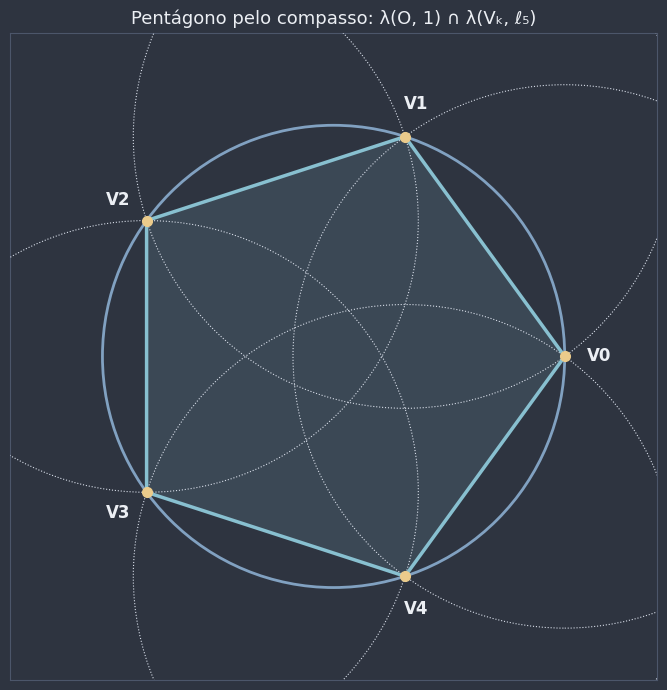

In [10]:
O_ex9 = np.array([0.0, 0.0])

# (a) ℓ₁₀ é a raiz positiva de ℓ² + ℓ − 1 = 0 (de ℓ₁₀² = R(R − ℓ₁₀) com R = 1)
l10_ex9 = (math.sqrt(5) - 1) / 2

# (b) Euclides: ℓ₅² = ℓ₆² + ℓ₁₀² = 1 + ℓ₁₀²
l5_ex9 = math.sqrt(1 + l10_ex9**2)

# (c) Compasso aberto em ℓ₅: cada vértice novo é o cruzamento de λ(O, 1) com λ(vértice atual, ℓ₅)
vertices_ex9 = [np.array([1.0, 0.0])]
for _ in range(4):
    vertices_ex9.append(cruzamento_circunferencias(O_ex9, 1, vertices_ex9[-1], l5_ex9))

# (d) A volta fecha se o último vértice estiver a ℓ₅ do primeiro
fecha_ex9 = iguais(math.dist(vertices_ex9[-1], vertices_ex9[0]), l5_ex9)

print(f"ℓ₁₀ = {l10_ex9:.6f} (medido: {lado_de_R(10, 1):.6f});  ℓ₁₀² = {l10_ex9**2:.6f} = 1 − ℓ₁₀ = {1 - l10_ex9:.6f}")
print(f"ℓ₅ = {l5_ex9:.6f} (medido: {lado_de_R(5, 1):.6f});  a volta fecha? {fecha_ex9}")

fig, ax = plt.subplots(figsize=(7, 7))
fig.patch.set_facecolor(NORD_FUNDO)
desenhar_circunferencia(ax, O_ex9, 1, cor=COR_CIRCUNSCRITA, largura=2)
for V in vertices_ex9:
    desenhar_circunferencia(ax, V, l5_ex9, cor=NORD_TEXTO_SEC, largura=0.8, estilo=":")
desenhar_poligono(ax, np.array(vertices_ex9))
for k, V in enumerate(vertices_ex9):
    desenhar_ponto(ax, V, cor=COR_AVISO)
    rotular_fora(ax, V, f"V{k}", O_ex9, distancia=0.15, tamanho=12)
preparar_eixo(ax, [(-1.3, -1.3), (1.3, 1.3)], margem=0.1)
ax.set_title("Pentágono pelo compasso: λ(O, 1) ∩ λ(Vₖ, ℓ₅)", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

**A dedução de $\ell_{10}$** (seção 2, curiosidade). No decágono, o triângulo $OAB$ tem $OA = OB = R$, $AB = \ell_{10}$ e ângulos $36°$ (em $O$), $72°$ e $72°$. A bissetriz de $\hat{B}$ corta $\overline{OA}$ em $D$, dividindo os $72°$ em $36° + 36°$.
- No triângulo $BDA$: os ângulos são $36°$ (em $B$), $72°$ (em $A$) e, portanto, $72°$ (em $D$). É isósceles com $BD = BA = \ell_{10}$ e é **semelhante** a $OAB$ (caso AA).
- No triângulo $ODB$: os ângulos em $O$ e em $B$ medem $36°$, então ele é isósceles com $OD = BD = \ell_{10}$, e sobra $DA = R - \ell_{10}$.
- A semelhança $BDA \sim OAB$ dá $\frac{DA}{AB} = \frac{AB}{OA}$, isto é, $\frac{R - \ell_{10}}{\ell_{10}} = \frac{\ell_{10}}{R}$, ou $\ell_{10}^2 + R\ell_{10} - R^2 = 0$. A raiz positiva (fórmula de Bhaskara, 0109a) é $\ell_{10} = R \cdot \frac{\sqrt{5} - 1}{2}$.

A relação de Euclides $\ell_5^2 = \ell_6^2 + \ell_{10}^2$ (os três lados formam um triângulo retângulo) aparece nos *Elementos*, Livro XIII; aqui ela foi **verificada** numericamente, e a construção mostra que, com o compasso aberto em $\ell_5$, a volta fecha em exatamente cinco passos.

**Exercício 10.** Para o mesmo perímetro, quem cerca mais área?

,n,área (perímetro 12)
0,3,6.9282
1,4,9.0000
2,5,9.9099
3,6,10.3923
4,8,10.8640
5,12,11.1962
6,24,11.3936
7,100,11.4554
8,1000,11.4591


True limite ≈ 11.459156   36/π = 11.459156


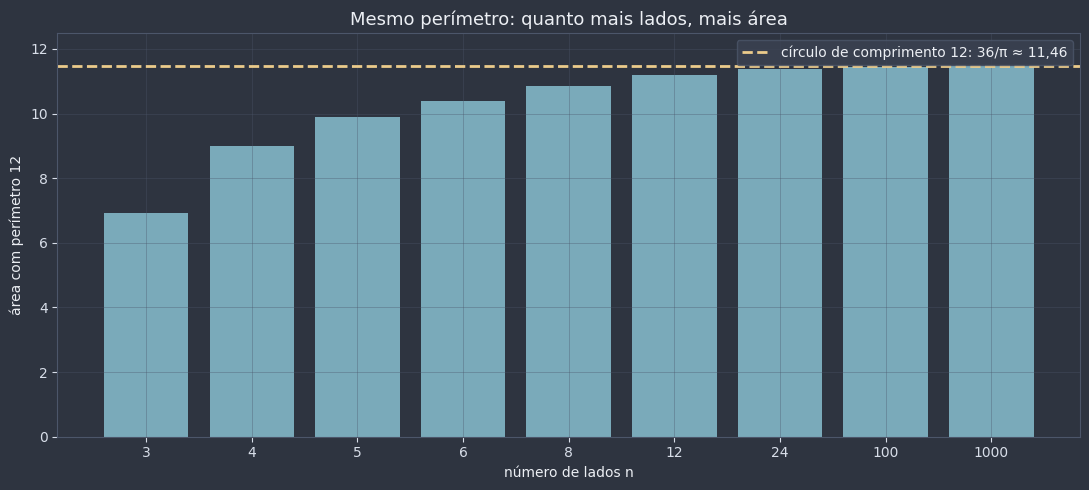

In [11]:
def area_com_perimetro(n: int, perimetro: float = 12.0) -> float:
    # Semelhança: ampliar o polígono de raio 1 até o perímetro desejado multiplica a área por k²
    k = perimetro / perimetro_regular(n, 1)
    return area_regular(n, 1) * k**2


ns_ex10 = (3, 4, 5, 6, 8, 12, 24, 100, 1000)
areas_ex10 = {n: area_com_perimetro(n) for n in ns_ex10}
crescente_ex10 = all(areas_ex10[a] < areas_ex10[b] for a, b in zip(ns_ex10, ns_ex10[1:]))
limite_ex10 = area_com_perimetro(100_000)

display(pd.DataFrame({"n": list(areas_ex10), "área (perímetro 12)": list(areas_ex10.values())}).round(4))
print(crescente_ex10, f"limite ≈ {limite_ex10:.6f}   36/π = {36 / math.pi:.6f}")

fig, ax = plt.subplots(figsize=(11, 5))
fig.patch.set_facecolor(NORD_FUNDO)
estilizar_eixo(ax)
ax.bar([str(n) for n in ns_ex10], list(areas_ex10.values()), color=COR_POLIGONO, alpha=0.85)
ax.axhline(36 / math.pi, color=COR_CENTRAL, lw=2, linestyle="--", label="círculo de comprimento 12: 36/π ≈ 11,46")
ax.set_ylim(0, 12.5)
ax.set_xlabel("número de lados n", color=NORD_TEXTO)
ax.set_ylabel("área com perímetro 12", color=NORD_TEXTO)
ax.legend(facecolor=NORD_PAINEL, edgecolor=NORD_LINHA, labelcolor=NORD_TEXTO)
ax.set_title("Mesmo perímetro: quanto mais lados, mais área", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

Triângulo $4\sqrt{3} \approx 6{,}93$, quadrado $9$, hexágono $6\sqrt{3} \approx 10{,}39$, e as áreas continuam crescendo com $n$, sempre abaixo de $\frac{36}{\pi} \approx 11{,}46$. Esse limite é a área do **círculo** cujo contorno mede 12: o raio é $r = \frac{12}{2\pi} = \frac{6}{\pi}$ e, pela fórmula que chega em [`0420a_areas_de_superficies_planas.ipynb`](0420a_areas_de_superficies_planas.ipynb) ($S = \pi r^2$), $S = \pi \cdot \frac{36}{\pi^2} = \frac{36}{\pi}$. É a **desigualdade isoperimétrica**: entre todas as figuras planas com o mesmo perímetro, o círculo é a que cerca mais área (a demonstração é difícil e fica fora do curso). Entre os três regulares que ladrilham, o hexágono é o vencedor, o que ajuda a explicar a "economia de cera" das abelhas da seção 2.